# CUSUM-Based Basket Trading Model

---

## Strategy Overview

| Parameter | Value |
|-----------|-------|
| **Universe** | 9 risk-on assets + 1 risk-off (TLT) |
| **Timeframe** | Daily (1D) |
| **Signal** | Rolling two-sided CUSUM on standardised returns |
| **Ranking** | CUSUM Momentum Score = $C^+_t - C^-_t$ |
| **Selection** | Top 3 assets by CUSUM momentum (score > 0) |
| **Risk-Off** | TLT (20Y Treasury ETF) -- absorbs unused weight |
| **Rebalancing** | Biweekly (every 10 trading days) |
| **Allocation** | Equal-weight among selected; remainder -> TLT |
| **Lookahead** | 1-day signal shift -- signal on day $t$, trade on day $t+1$ |
| **Vol Gate** | CUSUM on rolling vol -- halve exposure during vol alarms |

### Strategy Logic

1. Compute a **rolling two-sided CUSUM** for each of the 9 risk-on assets using a 63-day burn-in window
2. Calculate a **CUSUM Momentum Score** = $C^+ - C^-$ (upper minus lower detector)
3. **Shift signals by 1 day** to prevent lookahead bias
4. Every 10 trading days, **rank** all assets by their lagged CUSUM momentum
5. **Select top 3** with momentum score $> 0$ (upward trend detected)
6. **Equal-weight** the selected assets (33.3% each)
7. If fewer than 3 qualify, allocate remaining weight to **TLT** (risk-off)
8. If none qualify, go **100% TLT**
9. **Vol gate**: if CUSUM on rolling vol fires an alarm, halve risk-on weights

### Why CUSUM for Asset Selection?

| Property | Hurst Exponent | CUSUM Momentum |
|----------|---------------|----------------|
| Detects | Persistence (trending vs mean-reverting) | Sustained directional drift |
| Signal type | Scalar in [0, 1] | Signed momentum (direction + strength) |
| Sensitivity | Uniform across all shift sizes | Optimal for small persistent shifts |
| Memory | Fixed window (e.g., 63d) | Accumulates since last reset |
| False alarm control | None (heuristic threshold) | ARL0 calibrated via (k, h) |

CUSUM accumulates evidence of a shift -- so a high $C^+$ means returns have been **persistently above the in-control mean**, not just a single spike. This is a natural trend-following signal.

### Asset Universe

| # | Ticker | Asset | Role |
|---|--------|-------|------|
| 1 | BTC-USD | Bitcoin | Risk-on |
| 2 | QQQ | Nasdaq 100 ETF | Risk-on |
| 3 | SPY | S&P 500 ETF | Risk-on |
| 4 | AAPL | Apple | Risk-on |
| 5 | TSLA | Tesla | Risk-on |
| 6 | GLD | Gold ETF | Risk-on |
| 7 | NVDA | NVIDIA | Risk-on |
| 8 | AMZN | Amazon | Risk-on |
| 9 | XLE | Energy Sector ETF | Risk-on |
| 10 | **TLT** | **20Y Treasury ETF** | **Risk-off** |

### Lookahead Bias Prevention

```
Day t-63 to t-1 : returns used to estimate mu0, sigma0 (in-control params)
Day t           : CUSUM scores computed at close
Day t+1         : signal is shifted -> weights applied to return[t+1]
```

The 1-day shift ensures we **never trade on the same bar** that generated the signal.

In [1]:
# ============================================================
#  IMPORTS & CONFIGURATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (16, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})

# -- STRATEGY PARAMETERS --
ALL_TICKERS   = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA',
                 'GLD', 'NVDA', 'AMZN', 'XLE', 'TLT']
RISK_OFF      = 'TLT'
RISK_ON       = [t for t in ALL_TICKERS if t != RISK_OFF]

START_DATE    = '2018-01-01'
END_DATE      = '2025-01-01'
CUSUM_BURNIN  = 63          # burn-in window for mu0, sigma0
CUSUM_K       = 0.5         # allowance parameter (optimal for 1-sigma shift)
CUSUM_H       = 4.0         # decision threshold
REBAL_PERIOD  = 10          # Biweekly rebalancing
TOP_N         = 3           # Assets to hold
MIN_SCORE     = 0.0         # Minimum CUSUM momentum (C+ - C- > 0)
SIGNAL_LAG    = 1           # 1-day shift to prevent lookahead
INITIAL_CAP   = 100_000
VOL_GATE      = True        # Enable volatility alarm gate

print(f'Risk-on    : {len(RISK_ON)} assets -- {RISK_ON}')
print(f'Risk-off   : {RISK_OFF}')
print(f'Period     : {START_DATE} to {END_DATE}')
print(f'CUSUM      : k={CUSUM_K}, h={CUSUM_H}, burn-in={CUSUM_BURNIN}d')
print(f'Signal lag : {SIGNAL_LAG}d (lookahead protection)')
print(f'Selection  : top {TOP_N} with momentum > {MIN_SCORE}, remainder -> {RISK_OFF}')
print(f'Vol gate   : {"ON" if VOL_GATE else "OFF"}')

Risk-on    : 9 assets -- ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
Risk-off   : TLT
Period     : 2018-01-01 to 2025-01-01
CUSUM      : k=0.5, h=4.0, burn-in=63d
Signal lag : 1d (lookahead protection)
Selection  : top 3 with momentum > 0.0, remainder -> TLT
Vol gate   : ON


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


## 1. Data Download

In [2]:
# ============================================================
#  DOWNLOAD DAILY CLOSE PRICES
# ============================================================

close_prices = pd.DataFrame()
for ticker in ALL_TICKERS:
    df = yf.download(ticker, start=START_DATE, end=END_DATE,
                     progress=False, auto_adjust=True)
    if len(df) > 0:
        close_prices[ticker] = df['Close'].squeeze()

close_prices = close_prices.ffill().dropna()
returns = close_prices.pct_change().dropna()
log_returns = np.log(close_prices / close_prices.shift(1)).dropna()

print(f'Date range  : {close_prices.index[0].date()} to {close_prices.index[-1].date()}')
print(f'Trading days: {len(close_prices)}\n')
for t in close_prices.columns:
    role = 'RISK-OFF' if t == RISK_OFF else 'risk-on'
    pct = (close_prices[t].iloc[-1] / close_prices[t].iloc[0] - 1) * 100
    print(f'  {t:>8} [{role:>8}] | {close_prices[t].iloc[0]:>10,.2f} -> {close_prices[t].iloc[-1]:>10,.2f} | {pct:>+8.1f}%')

Date range  : 2018-01-02 to 2024-12-31
Trading days: 2556

   BTC-USD [ risk-on] |  14,982.10 ->  93,429.20 |   +523.6%
       QQQ [ risk-on] |     150.22 ->     508.01 |   +238.2%
       SPY [ risk-on] |     236.56 ->     577.70 |   +144.2%
      AAPL [ risk-on] |      40.30 ->     249.06 |   +517.9%
      TSLA [ risk-on] |      21.37 ->     403.84 |  +1789.9%
       GLD [ risk-on] |     125.15 ->     242.13 |    +93.5%
      NVDA [ risk-on] |       4.93 ->     134.25 |  +2624.0%
      AMZN [ risk-on] |      59.45 ->     219.39 |   +269.0%
       XLE [ risk-on] |      25.75 ->      41.18 |    +59.9%
       TLT [RISK-OFF] |      99.46 ->      82.68 |    -16.9%


### Normalized Price Chart

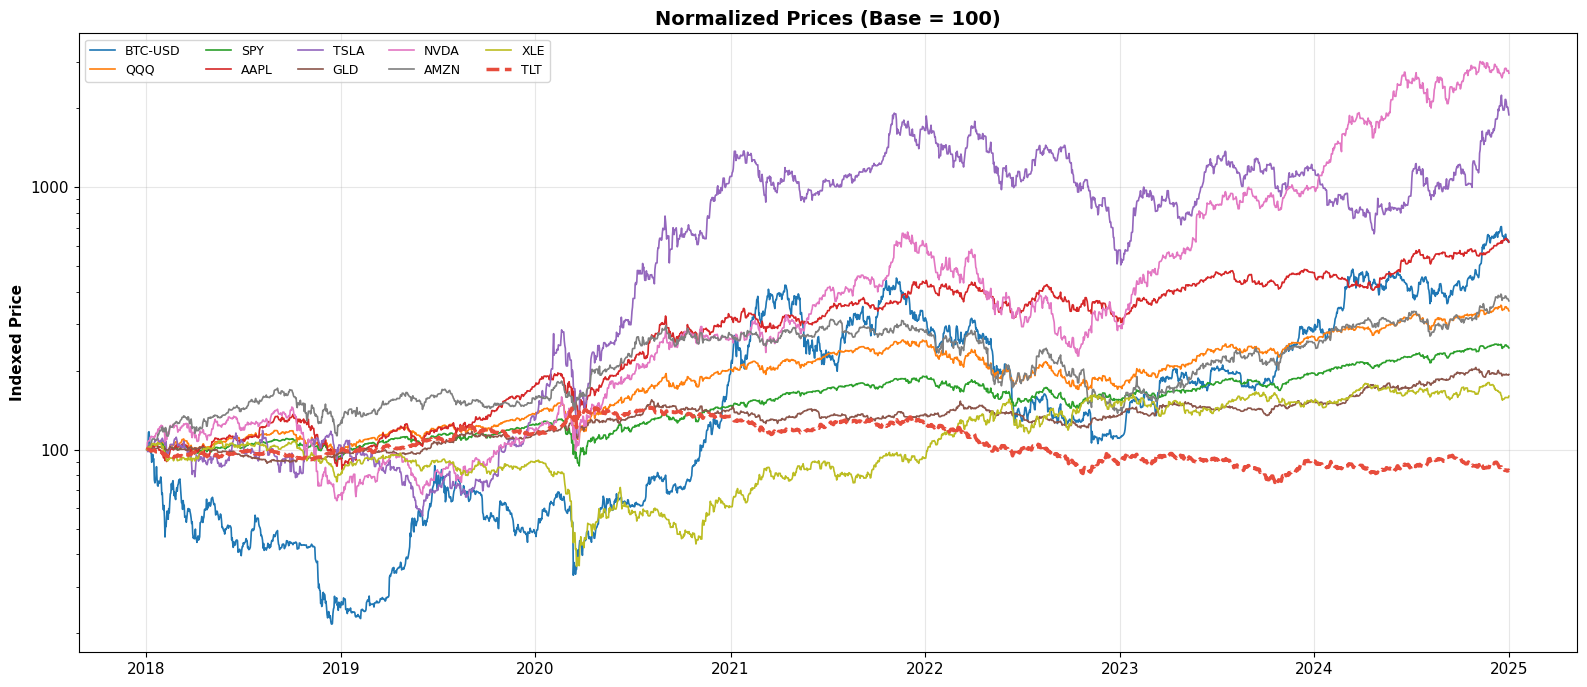

In [3]:
norm = close_prices / close_prices.iloc[0] * 100
fig, ax = plt.subplots(figsize=(16, 7))
for col in norm.columns:
    style = {'linewidth': 2.5, 'linestyle': '--', 'color': '#e74c3c'} if col == RISK_OFF else {'linewidth': 1.2}
    ax.plot(norm.index, norm[col], label=col, **style)
ax.set_title('Normalized Prices (Base = 100)', fontsize=14)
ax.set_ylabel('Indexed Price'); ax.set_yscale('log')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}'))
ax.legend(ncol=5, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 2. Rolling CUSUM Momentum Score

For each risk-on asset, we run a **two-sided CUSUM** on its log returns:

$$C_t^+ = \max\!\big(0,\; C_{t-1}^+ + y_t - k\big), \qquad C_t^- = \max\!\big(0,\; C_{t-1}^- - y_t - k\big)$$

where $y_t = (r_t - \hat\mu_0) / \hat\sigma_0$ is the standardised return (using a rolling burn-in estimate).

The **CUSUM Momentum Score** is:

$$M_t = C_t^+ - C_t^-$$

- $M_t > 0$ : accumulated evidence of **upward drift** (bullish)
- $M_t < 0$ : accumulated evidence of **downward drift** (bearish)
- $M_t \approx 0$ : no persistent shift detected (neutral)

**Key**: after computing, we **shift the signal by 1 day** so that the score computed at close of day $t$ is only used for trading on day $t+1$.

In [4]:
# ============================================================
#  CUSUM ENGINE -- TWO-SIDED WITH ROLLING BURN-IN
# ============================================================

def cusum_two_sided(x, k=0.5, h=4.0, mu0=None, sigma=None, reset=True):
    # Two-sided CUSUM on series x.
    # Returns: C_upper, C_lower, up_signals, down_signals
    x = np.asarray(x, dtype=float)
    if mu0 is not None and sigma is not None:
        y = (x - mu0) / sigma
    else:
        y = (x - np.nanmean(x)) / np.nanstd(x)

    n = len(y)
    Cu = np.zeros(n)
    Cl = np.zeros(n)
    up_sigs, dn_sigs = [], []

    for i in range(1, n):
        Cu[i] = max(0.0, Cu[i-1] + y[i] - k)
        Cl[i] = max(0.0, Cl[i-1] - y[i] - k)
        if Cu[i] > h:
            up_sigs.append(i)
            if reset:
                Cu[i] = 0.0
        if Cl[i] > h:
            dn_sigs.append(i)
            if reset:
                Cl[i] = 0.0

    return Cu, Cl, np.array(up_sigs), np.array(dn_sigs)


def compute_rolling_cusum_momentum(returns_df, burnin, k, h):
    # Compute rolling CUSUM momentum score (C_upper - C_lower) for each asset.
    # Uses the first 'burnin' observations for in-control parameter estimation.
    result = {}
    for col in returns_df.columns:
        vals = returns_df[col].values
        n = len(vals)
        momentum = np.full(n, np.nan)
        Cu, Cl = 0.0, 0.0

        for i in range(burnin, n):
            # Fix in-control params from burn-in only (no look-ahead)
            if i == burnin:
                mu0 = np.mean(vals[:burnin])
                sig0 = np.std(vals[:burnin], ddof=1)
                if sig0 < 1e-10:
                    sig0 = 1e-10

            y = (vals[i] - mu0) / sig0
            Cu = max(0.0, Cu + y - k)
            Cl = max(0.0, Cl - y - k)

            # Record momentum BEFORE reset
            momentum[i] = Cu - Cl

            if Cu > h:
                Cu = 0.0
            if Cl > h:
                Cl = 0.0

        result[col] = momentum
    return pd.DataFrame(result, index=returns_df.index)


def compute_vol_alarm(returns_df, burnin, k=0.5, h=4.0, window=21):
    # CUSUM-based volatility alarm for each asset.
    # Runs one-sided CUSUM on squared returns.
    # Returns boolean DataFrame (True = alarm active).
    result = {}
    for col in returns_df.columns:
        vals = returns_df[col].values
        sq = vals ** 2
        n = len(sq)
        alarm = np.zeros(n, dtype=bool)

        mu0_sq = np.mean(sq[:burnin])
        sig_sq = np.std(sq[:burnin], ddof=1)
        if sig_sq < 1e-15:
            sig_sq = 1e-15

        Cu = 0.0
        for i in range(burnin, n):
            y = (sq[i] - mu0_sq) / sig_sq
            Cu = max(0.0, Cu + y - k)
            if Cu > h:
                alarm[i:min(i + window, n)] = True
                Cu = 0.0

        result[col] = alarm
    return pd.DataFrame(result, index=returns_df.index)


# -- Compute for risk-on tickers only --
risk_on_returns = log_returns[RISK_ON]
print(f'Computing rolling CUSUM momentum (k={CUSUM_K}, h={CUSUM_H}, burn-in={CUSUM_BURNIN}) '
      f'for {len(RISK_ON)} risk-on assets...')

cusum_raw = compute_rolling_cusum_momentum(risk_on_returns, CUSUM_BURNIN, CUSUM_K, CUSUM_H)

# Compute vol alarms
vol_alarms = compute_vol_alarm(risk_on_returns, CUSUM_BURNIN, k=0.5, h=4.0, window=21)

# -- CRITICAL: Shift signal by SIGNAL_LAG days to prevent lookahead --
cusum_df = cusum_raw.shift(SIGNAL_LAG)
cusum_df = cusum_df.dropna(how='all')
vol_alarm_df = vol_alarms.shift(SIGNAL_LAG).fillna(False)

print(f'Done: {len(cusum_df)} obs x {len(cusum_df.columns)} assets')
print(f'Signal lag : {SIGNAL_LAG} day(s) applied')
print(f'\nLatest CUSUM momentum (ranked, after lag):')
latest = cusum_df.iloc[-1].sort_values(ascending=False)
print(latest.to_string())
print(f'\nVol alarm active now: {vol_alarm_df.iloc[-1].sum()} / {len(RISK_ON)} assets')

Computing rolling CUSUM momentum (k=0.5, h=4.0, burn-in=63) for 9 risk-on assets...
Done: 2491 obs x 9 assets
Signal lag : 1 day(s) applied

Latest CUSUM momentum (ranked, after lag):
BTC-USD    0.000000
XLE        0.000000
NVDA       0.000000
GLD       -0.123886
AAPL      -0.506658
SPY       -0.624118
QQQ       -0.735548
AMZN      -1.180658
TSLA      -2.686825

Vol alarm active now: 2 / 9 assets


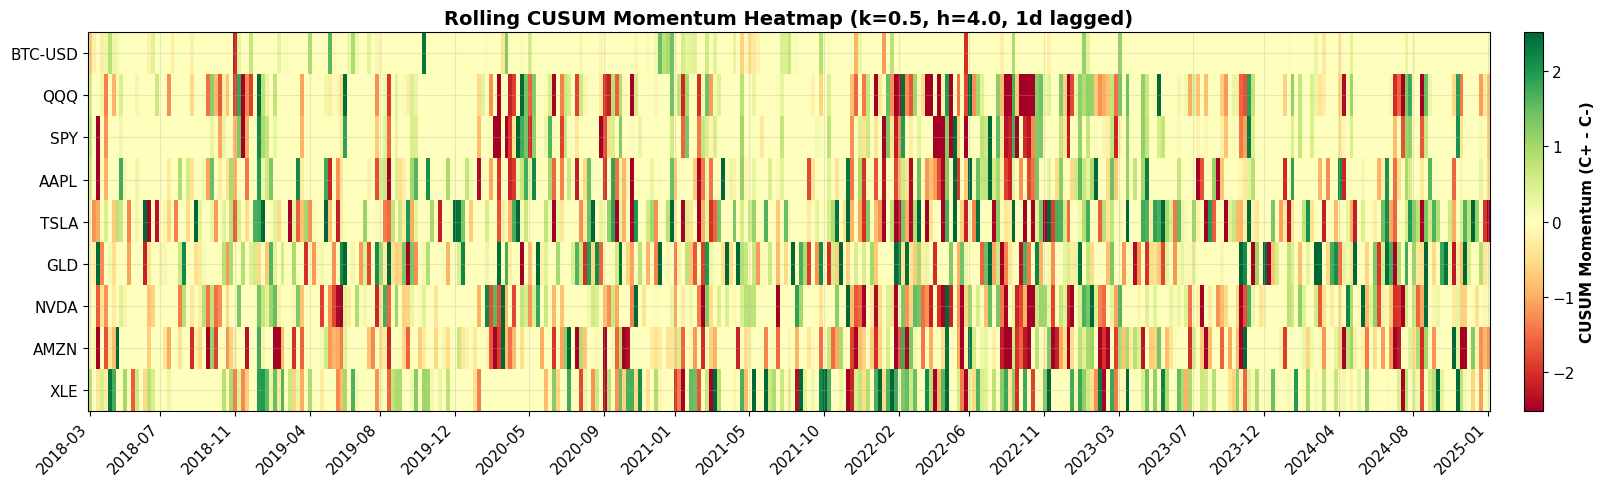

In [5]:
# ============================================================
#  CUSUM MOMENTUM HEATMAP
# ============================================================

hw = cusum_df.resample('W').last().dropna(how='all')
fig, ax = plt.subplots(figsize=(18, 5))
vmax = np.nanpercentile(np.abs(hw.values), 95)
im = ax.imshow(hw.T.values, aspect='auto', cmap='RdYlGn',
               vmin=-vmax, vmax=vmax, interpolation='nearest')
ax.set_yticks(range(len(hw.columns))); ax.set_yticklabels(hw.columns)
ti = np.linspace(0, len(hw)-1, 20, dtype=int)
ax.set_xticks(ti)
ax.set_xticklabels([hw.index[i].strftime('%Y-%m') for i in ti], rotation=45, ha='right')
plt.colorbar(im, ax=ax, pad=0.02).set_label('CUSUM Momentum (C+ - C-)')
ax.set_title(f'Rolling CUSUM Momentum Heatmap (k={CUSUM_K}, h={CUSUM_H}, 1d lagged)', fontsize=14)
plt.tight_layout(); plt.show()

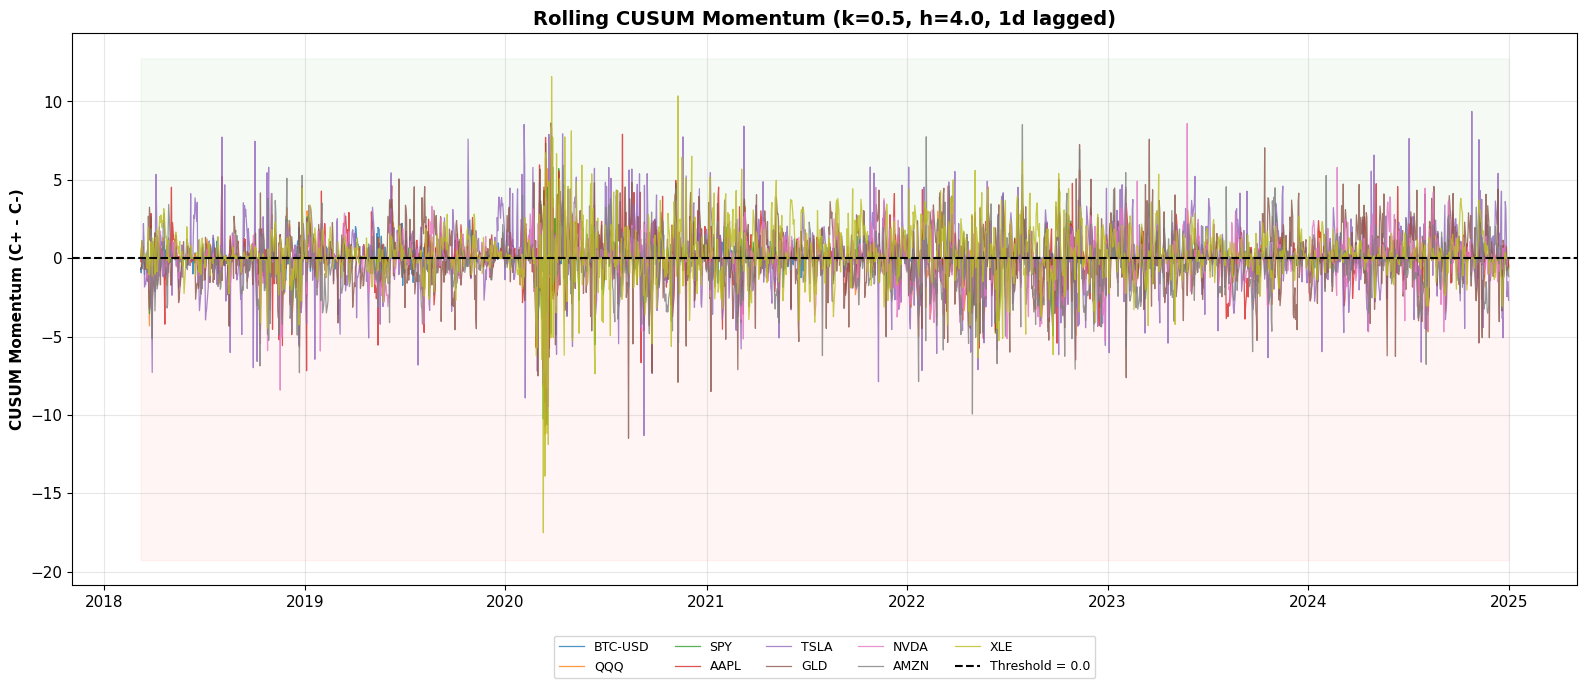

In [6]:
# ============================================================
#  CUSUM MOMENTUM LINE CHART
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))
for col in cusum_df.columns:
    ax.plot(cusum_df.index, cusum_df[col], lw=0.9, alpha=0.8, label=col)
ax.axhline(MIN_SCORE, color='black', lw=1.5, ls='--', label=f'Threshold = {MIN_SCORE}')
ax.fill_between(cusum_df.index, MIN_SCORE, cusum_df.max().max() * 1.1,
                alpha=0.04, color='green')
ax.fill_between(cusum_df.index, cusum_df.min().min() * 1.1, MIN_SCORE,
                alpha=0.04, color='red')
ax.set_ylabel('CUSUM Momentum (C+ - C-)')
ax.set_title(f'Rolling CUSUM Momentum (k={CUSUM_K}, h={CUSUM_H}, 1d lagged)', fontsize=14)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

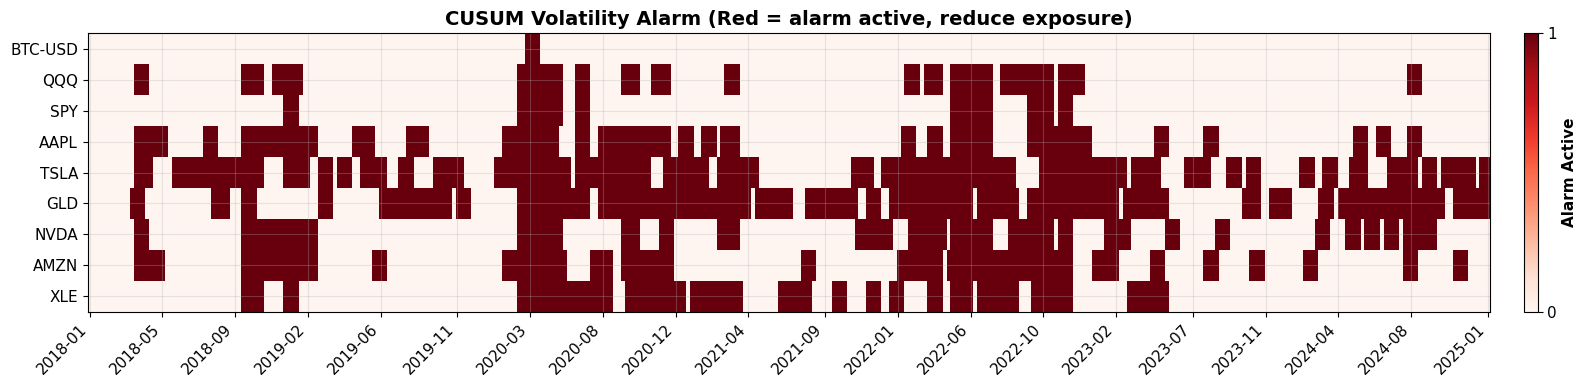

Percentage of time under vol alarm per asset:
   BTC-USD: 0.8%
       QQQ: 21.1%
       SPY: 9.5%
      AAPL: 35.5%
      TSLA: 59.3%
       GLD: 60.2%
      NVDA: 30.9%
      AMZN: 35.5%
       XLE: 30.5%


In [7]:
# ============================================================
#  VOLATILITY ALARM HEATMAP
# ============================================================

va = vol_alarm_df.resample('W').max().dropna(how='all').astype(float)
fig, ax = plt.subplots(figsize=(18, 4))
im = ax.imshow(va.T.values, aspect='auto', cmap='Reds',
               vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(len(va.columns))); ax.set_yticklabels(va.columns)
ti = np.linspace(0, len(va)-1, 20, dtype=int)
ax.set_xticks(ti)
ax.set_xticklabels([va.index[i].strftime('%Y-%m') for i in ti], rotation=45, ha='right')
plt.colorbar(im, ax=ax, pad=0.02, ticks=[0, 1]).set_label('Alarm Active')
ax.set_title('CUSUM Volatility Alarm (Red = alarm active, reduce exposure)', fontsize=14)
plt.tight_layout(); plt.show()

# Summary
pct_alarm = vol_alarm_df.mean() * 100
print('Percentage of time under vol alarm per asset:')
for col in pct_alarm.index:
    print(f'  {col:>8}: {pct_alarm[col]:.1f}%')

## 3. Backtest Engine

**No data leakage**: CUSUM signals are already shifted by 1 day. On any day, the backtest only sees yesterday's CUSUM momentum.

| Scenario | Risk-On Weight | TLT Weight |
|----------|---------------|------------|
| 3 assets qualify | 100% (33.3% x 3) | 0% |
| 2 assets qualify | 66.7% (33.3% x 2) | 33.3% |
| 1 asset qualifies | 33.3% | 66.7% |
| 0 assets qualify | 0% | **100%** |

**Vol gate**: if any selected asset has an active CUSUM vol alarm, its weight is halved and the freed weight goes to TLT.

In [8]:
# ============================================================
#  BACKTEST ENGINE (WITH TLT RISK-OFF + VOL GATE)
# ============================================================

def run_backtest(returns_df, cusum_df, vol_alarm_df, risk_off_ticker,
                 top_n, rebal_period, min_score, vol_gate=True):
    # CUSUM basket backtest with risk-off and volatility gating.
    # cusum_df is ALREADY lagged -- no additional shift needed.
    common_idx = returns_df.index.intersection(cusum_df.index)
    ret = returns_df.loc[common_idx]
    cdf = cusum_df.loc[common_idx]
    vdf = vol_alarm_df.reindex(common_idx).fillna(False)

    all_assets = list(ret.columns)
    n_days = len(ret)

    port_ret_arr = np.zeros(n_days)
    weight_arr = np.zeros((n_days, len(all_assets)))
    asset_idx = {a: i for i, a in enumerate(all_assets)}
    rebal_log = []

    cur_w = np.zeros(len(all_assets))
    cur_w[asset_idx[risk_off_ticker]] = 1.0
    days_since = rebal_period  # Force first rebalance

    ret_vals = ret.values  # numpy for speed

    for i in range(n_days):
        days_since += 1
        date = ret.index[i]

        if days_since >= rebal_period:
            scores = cdf.iloc[i].dropna()

            # Rank by CUSUM momentum, select positive momentum assets
            positive = scores[scores > min_score].sort_values(ascending=False)
            selected = positive.head(top_n)
            n_sel = len(selected)

            cur_w[:] = 0.0
            unit_w = 1.0 / top_n

            for ticker in selected.index:
                w = unit_w
                # Vol gate: halve weight if vol alarm is active
                if vol_gate and ticker in vdf.columns:
                    if vdf.iloc[i].get(ticker, False):
                        w *= 0.5
                cur_w[asset_idx[ticker]] = w

            # Remaining weight -> TLT
            risk_off_w = 1.0 - cur_w.sum()
            cur_w[asset_idx[risk_off_ticker]] = risk_off_w

            rebal_log.append({
                'date': date,
                'selected': list(selected.index),
                'cusum_scores': selected.to_dict(),
                'n_selected': n_sel,
                'tlt_weight': risk_off_w,
                'vol_gated': sum(1 for t in selected.index
                                 if vol_gate and t in vdf.columns
                                 and vdf.iloc[i].get(t, False)),
            })
            days_since = 0

        port_ret_arr[i] = np.dot(cur_w, ret_vals[i])
        weight_arr[i] = cur_w.copy()

    port_ret = pd.Series(port_ret_arr, index=ret.index)
    weights = pd.DataFrame(weight_arr, index=ret.index, columns=all_assets)

    return port_ret, weights, rebal_log


# -- Run the backtest --
port_ret, holdings, rebal_log = run_backtest(
    returns, cusum_df, vol_alarm_df, RISK_OFF,
    TOP_N, REBAL_PERIOD, MIN_SCORE, VOL_GATE
)

equity = (1 + port_ret).cumprod() * INITIAL_CAP
spy_ret = returns['SPY'].reindex(port_ret.index).fillna(0)
spy_equity = (1 + spy_ret).cumprod() * INITIAL_CAP

# Risk-off stats
tlt_weights = [r['tlt_weight'] for r in rebal_log]
pct_full_riskon = sum(1 for w in tlt_weights if w < 0.01) / len(tlt_weights) * 100
pct_full_riskoff = sum(1 for w in tlt_weights if w >= 0.99) / len(tlt_weights) * 100
vol_gated_count = sum(r['vol_gated'] for r in rebal_log)

print(f'Backtest complete: {len(rebal_log)} rebalances')
print(f'\nFinal equity: ${equity.iloc[-1]:,.0f}  |  SPY B&H: ${spy_equity.iloc[-1]:,.0f}')
print(f'\nRisk-off stats:')
print(f'  Avg TLT weight     : {np.mean(tlt_weights):.1%}')
print(f'  Fully risk-on      : {pct_full_riskon:.1f}% of rebalances')
print(f'  Fully risk-off     : {pct_full_riskoff:.1f}% of rebalances (100% TLT)')
print(f'  Vol-gated events   : {vol_gated_count} (weight halved due to vol alarm)')

Backtest complete: 250 rebalances

Final equity: $356,759  |  SPY B&H: $240,616

Risk-off stats:
  Avg TLT weight     : 47.5%
  Fully risk-on      : 14.8% of rebalances
  Fully risk-off     : 16.4% of rebalances (100% TLT)
  Vol-gated events   : 210 (weight halved due to vol alarm)


## 4. Performance -- CUSUM Strategy vs SPY Buy & Hold

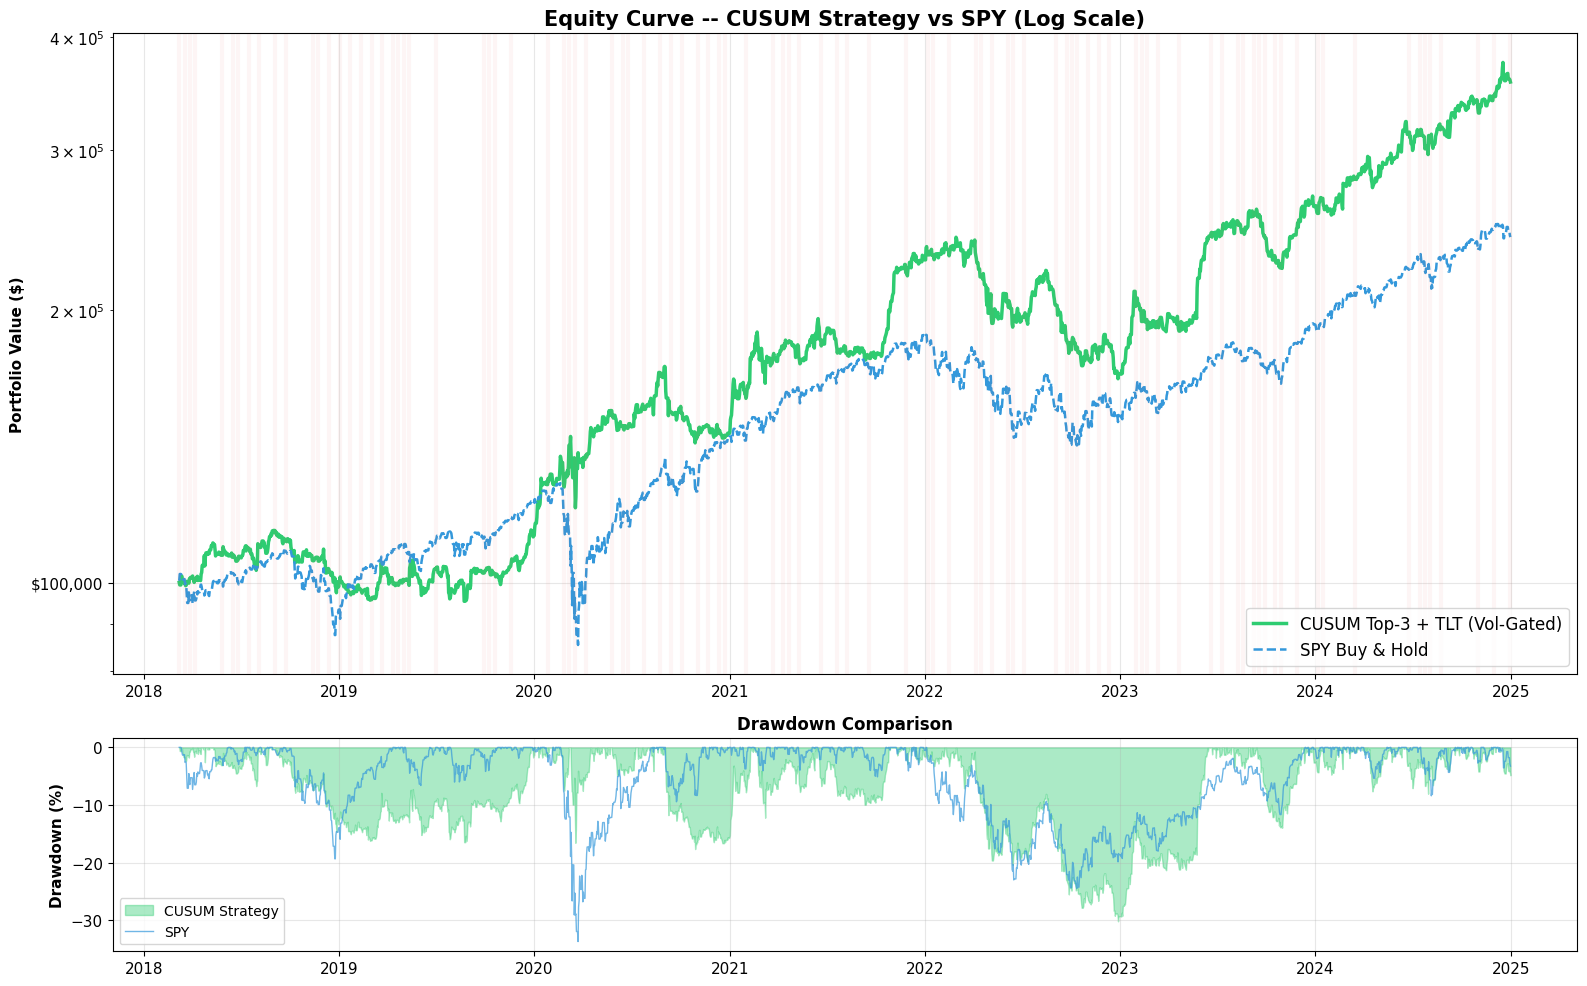

In [9]:
# ============================================================
#  EQUITY CURVE (LOG SCALE) + DRAWDOWN
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10),
                                gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(equity.index, equity, color='#2ecc71', lw=2.5,
         label=f'CUSUM Top-{TOP_N} + TLT (Vol-Gated)')
ax1.plot(spy_equity.index, spy_equity, color='#3498db', lw=1.8,
         linestyle='--', label='SPY Buy & Hold')

# Shade heavy risk-off periods
for r in rebal_log:
    if r['tlt_weight'] > 0.5:
        ax1.axvline(r['date'], color='#e74c3c', alpha=0.05, lw=3)

ax1.set_yscale('log')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'${y:,.0f}'))
ax1.set_title('Equity Curve -- CUSUM Strategy vs SPY (Log Scale)', fontsize=15)
ax1.set_ylabel('Portfolio Value ($)')
ax1.legend(fontsize=12)

# Drawdown
dd_strat = (equity / equity.cummax() - 1) * 100
dd_spy   = (spy_equity / spy_equity.cummax() - 1) * 100
ax2.fill_between(dd_strat.index, dd_strat, 0, color='#2ecc71', alpha=0.4,
                 label='CUSUM Strategy')
ax2.plot(dd_spy.index, dd_spy, color='#3498db', lw=1, alpha=0.7, label='SPY')
ax2.set_ylabel('Drawdown (%)'); ax2.set_title('Drawdown Comparison', fontsize=12)
ax2.legend(fontsize=10)

plt.tight_layout(); plt.show()

In [10]:
# ============================================================
#  PERFORMANCE METRICS TABLE
# ============================================================

def calc_metrics(ret_s, name, rf=0.04):
    r = ret_s.dropna(); n = len(r)
    eq = (1 + r).cumprod(); yrs = n / 252
    tot = eq.iloc[-1] - 1
    cagr = (1 + tot) ** (1 / yrs) - 1
    vol = r.std() * np.sqrt(252)
    rfd = (1 + rf) ** (1/252) - 1
    sharpe = (r.mean() - rfd) / r.std() * np.sqrt(252) if r.std() > 0 else 0
    ds = r[r < 0].std() * np.sqrt(252)
    sortino = (cagr - rf) / ds if ds > 0 else 0
    dd = eq / eq.cummax() - 1; mdd = dd.min()
    calmar = cagr / abs(mdd) if abs(mdd) > 0 else 0
    wr = (r > 0).mean()
    g = r[r > 0].sum(); l = abs(r[r < 0].sum())
    pf = g / l if l > 0 else float('inf')
    return {'Strategy': name, 'CAGR': f'{cagr:.1%}', 'Vol': f'{vol:.1%}',
            'Sharpe': f'{sharpe:.2f}', 'Sortino': f'{sortino:.2f}',
            'Max DD': f'{mdd:.1%}', 'Calmar': f'{calmar:.2f}',
            'Win Rate': f'{wr:.1%}', 'Profit Factor': f'{pf:.2f}',
            'Total Return': f'{tot:.1%}'}

metrics = pd.DataFrame([
    calc_metrics(port_ret, f'CUSUM Top-{TOP_N} + TLT (Gated)'),
    calc_metrics(spy_ret, 'SPY Buy & Hold'),
]).set_index('Strategy')

print('\n' + '='*90)
print('PERFORMANCE COMPARISON')
print('='*90)
print(metrics.to_string())


PERFORMANCE COMPARISON
                            CAGR    Vol Sharpe Sortino  Max DD Calmar Win Rate Profit Factor Total Return
Strategy                                                                                                 
CUSUM Top-3 + TLT (Gated)  13.7%  17.1%   0.61    0.73  -30.2%   0.45    37.3%          1.20       256.8%
SPY Buy & Hold              9.3%  16.2%   0.39    0.33  -33.7%   0.28    37.9%          1.16       140.6%


## 5. Holdings & Allocation Analysis

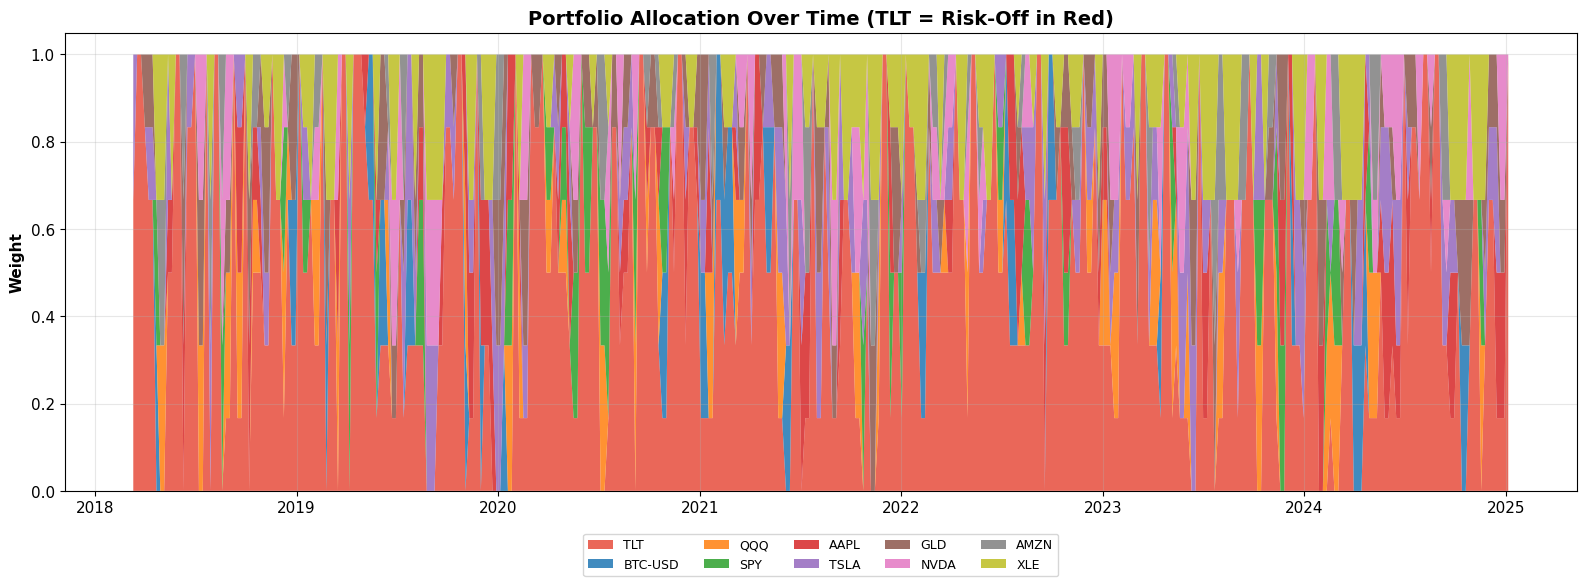

In [11]:
# ============================================================
#  HOLDINGS STACKED AREA (TLT HIGHLIGHTED)
# ============================================================

wk = holdings.resample('W').last().dropna(how='all').fillna(0)
cols = [RISK_OFF] + [c for c in wk.columns if c != RISK_OFF]
wk = wk[cols]

fig, ax = plt.subplots(figsize=(16, 6))
colors = ['#e74c3c'] + [plt.cm.tab10(i) for i in range(len(cols)-1)]
ax.stackplot(wk.index, [wk[c] for c in wk.columns],
             labels=wk.columns, colors=colors, alpha=0.85)
ax.set_title('Portfolio Allocation Over Time (TLT = Risk-Off in Red)', fontsize=14)
ax.set_ylabel('Weight'); ax.set_ylim(0, 1.05)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout(); plt.show()

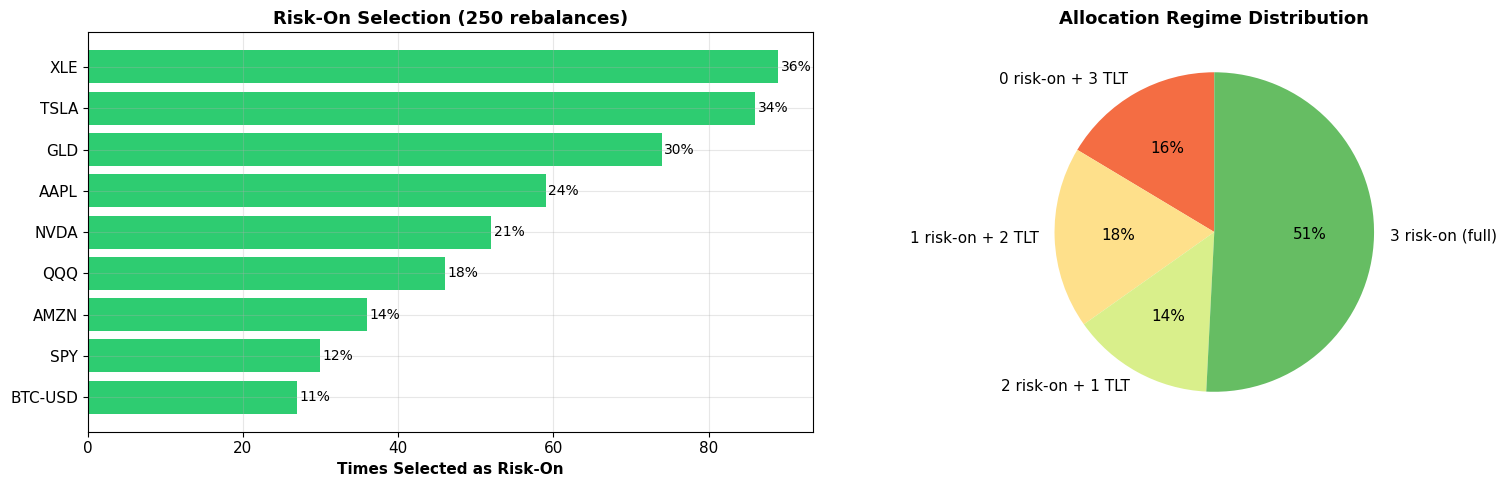

TLT held (any weight) in 213/250 rebalances (85%)


In [12]:
# ============================================================
#  SELECTION FREQUENCY + RISK-OFF ALLOCATION
# ============================================================

all_sel = [t for r in rebal_log for t in r['selected']]
freq = Counter(all_sel)
total = len(rebal_log)
tlt_times = sum(1 for r in rebal_log if r['tlt_weight'] > 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

tickers_sorted = [t for t, _ in freq.most_common()]
counts_sorted  = [c for _, c in freq.most_common()]
ax1.barh(tickers_sorted, counts_sorted, color='#2ecc71')
ax1.set_xlabel('Times Selected as Risk-On')
ax1.set_title(f'Risk-On Selection ({total} rebalances)', fontsize=13)
ax1.invert_yaxis()
for i, (t, c) in enumerate(zip(tickers_sorted, counts_sorted)):
    ax1.text(c + 0.3, i, f'{c/total:.0%}', va='center', fontsize=10)

n_counts = Counter(r['n_selected'] for r in rebal_log)
labels = [f'{n} risk-on + {TOP_N-n} TLT' if n < TOP_N else f'{n} risk-on (full)'
          for n in sorted(n_counts.keys())]
sizes = [n_counts[n] for n in sorted(n_counts.keys())]
ax2.pie(sizes, labels=labels, autopct='%1.0f%%', startangle=90,
        colors=plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(sizes))))
ax2.set_title('Allocation Regime Distribution', fontsize=13)

plt.tight_layout(); plt.show()
print(f'TLT held (any weight) in {tlt_times}/{total} rebalances ({tlt_times/total:.0%})')

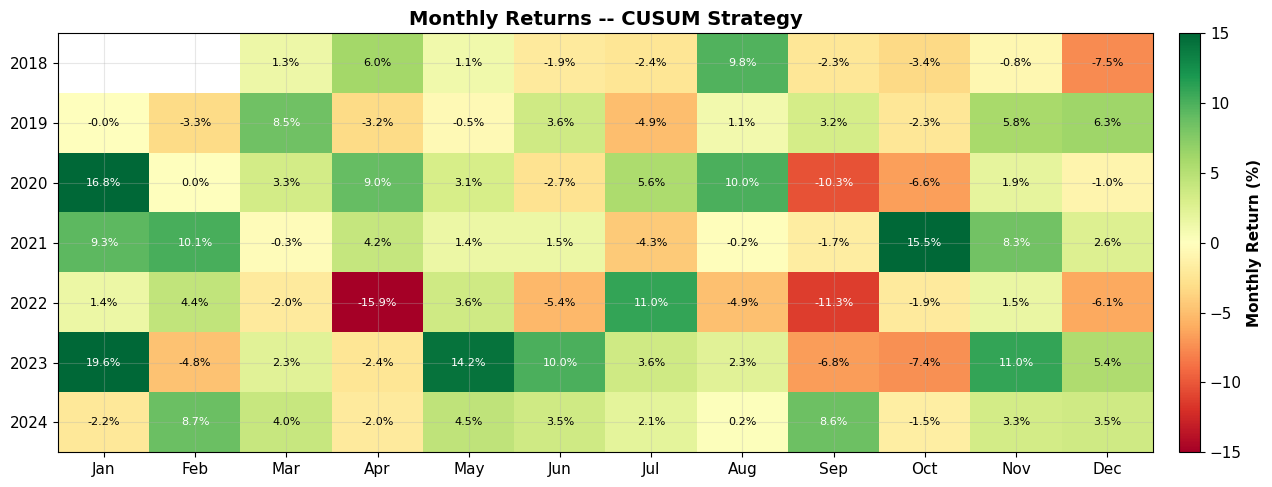

In [13]:
# ============================================================
#  MONTHLY RETURNS HEATMAP
# ============================================================

mo = port_ret.resample('ME').apply(lambda x: (1+x).prod()-1)
mdf = pd.DataFrame({'Year': mo.index.year, 'Month': mo.index.month, 'Return': mo.values})
pv = mdf.pivot_table(values='Return', index='Year', columns='Month')
pv.columns = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'][:len(pv.columns)]

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(pv.values*100, cmap='RdYlGn', aspect='auto', vmin=-15, vmax=15)
ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
for i in range(len(pv.index)):
    for j in range(len(pv.columns)):
        v = pv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v*100:.1f}%', ha='center', va='center',
                    fontsize=8, color='black' if abs(v) < 0.08 else 'white')
plt.colorbar(im, ax=ax, pad=0.02).set_label('Monthly Return (%)')
ax.set_title('Monthly Returns -- CUSUM Strategy', fontsize=14)
plt.tight_layout(); plt.show()

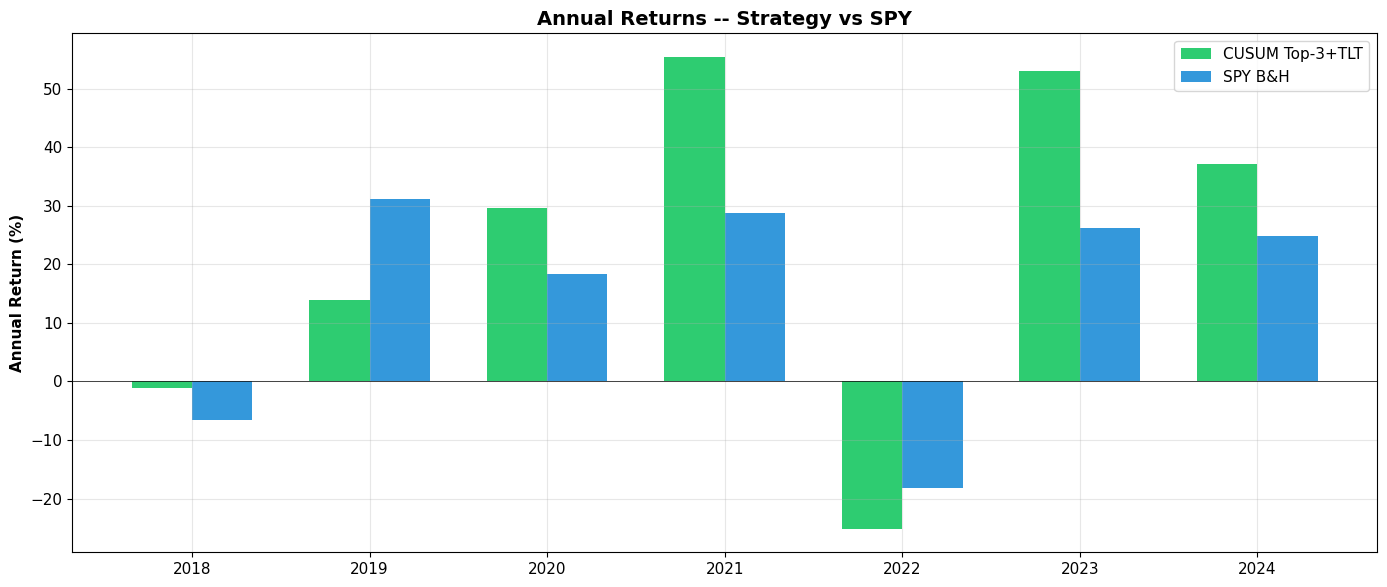

In [14]:
# ============================================================
#  ANNUAL RETURNS COMPARISON
# ============================================================

ann_s = port_ret.resample('YE').apply(lambda x: (1+x).prod()-1)
ann_spy = spy_ret.resample('YE').apply(lambda x: (1+x).prod()-1)
yrs = ann_s.index.year; x = np.arange(len(yrs))

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - 0.17, ann_s.values * 100, 0.34,
       label=f'CUSUM Top-{TOP_N}+TLT', color='#2ecc71')
ax.bar(x + 0.17, ann_spy.values * 100, 0.34,
       label='SPY B&H', color='#3498db')
ax.set_xticks(x); ax.set_xticklabels(yrs)
ax.set_ylabel('Annual Return (%)'); ax.axhline(0, color='black', lw=0.5)
ax.set_title('Annual Returns -- Strategy vs SPY', fontsize=14)
ax.legend(); plt.tight_layout(); plt.show()

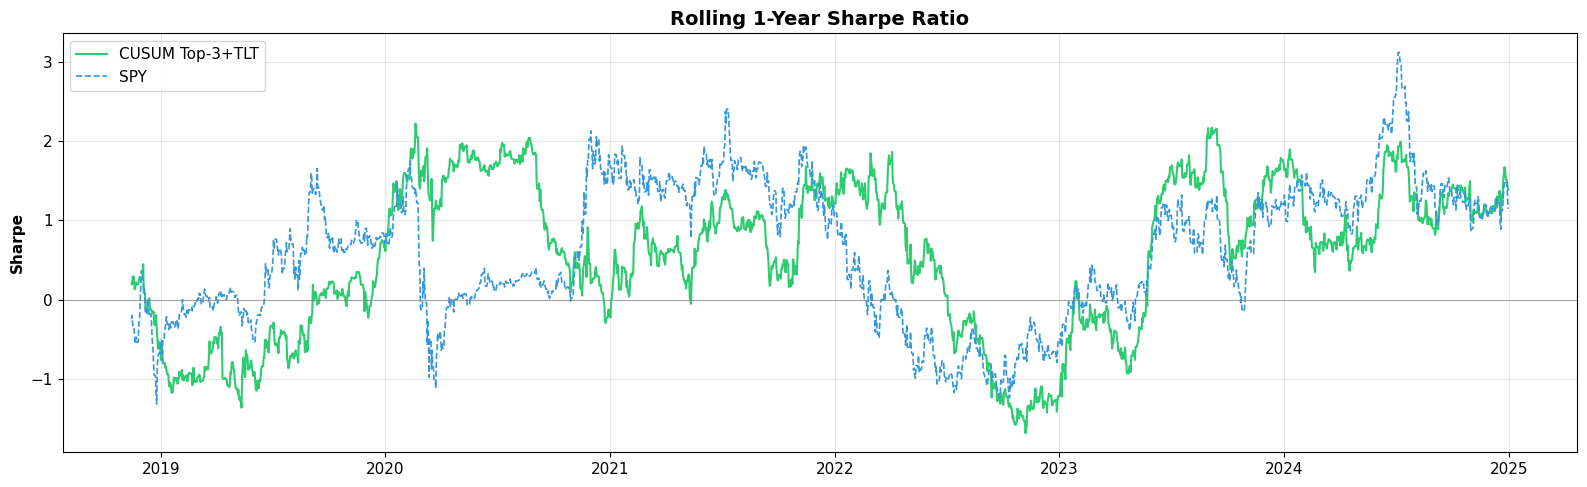

In [15]:
# ============================================================
#  ROLLING 1-YEAR SHARPE
# ============================================================

rfd = (1.04) ** (1/252) - 1
rs_s = (port_ret.rolling(252).mean() - rfd) / port_ret.rolling(252).std() * np.sqrt(252)
rs_spy = (spy_ret.rolling(252).mean() - rfd) / spy_ret.rolling(252).std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(rs_s.index, rs_s, color='#2ecc71', lw=1.5,
        label=f'CUSUM Top-{TOP_N}+TLT')
ax.plot(rs_spy.index, rs_spy, color='#3498db', lw=1.2, ls='--', label='SPY')
ax.axhline(0, color='gray', lw=0.5)
ax.set_title('Rolling 1-Year Sharpe Ratio', fontsize=14)
ax.set_ylabel('Sharpe'); ax.legend()
plt.tight_layout(); plt.show()

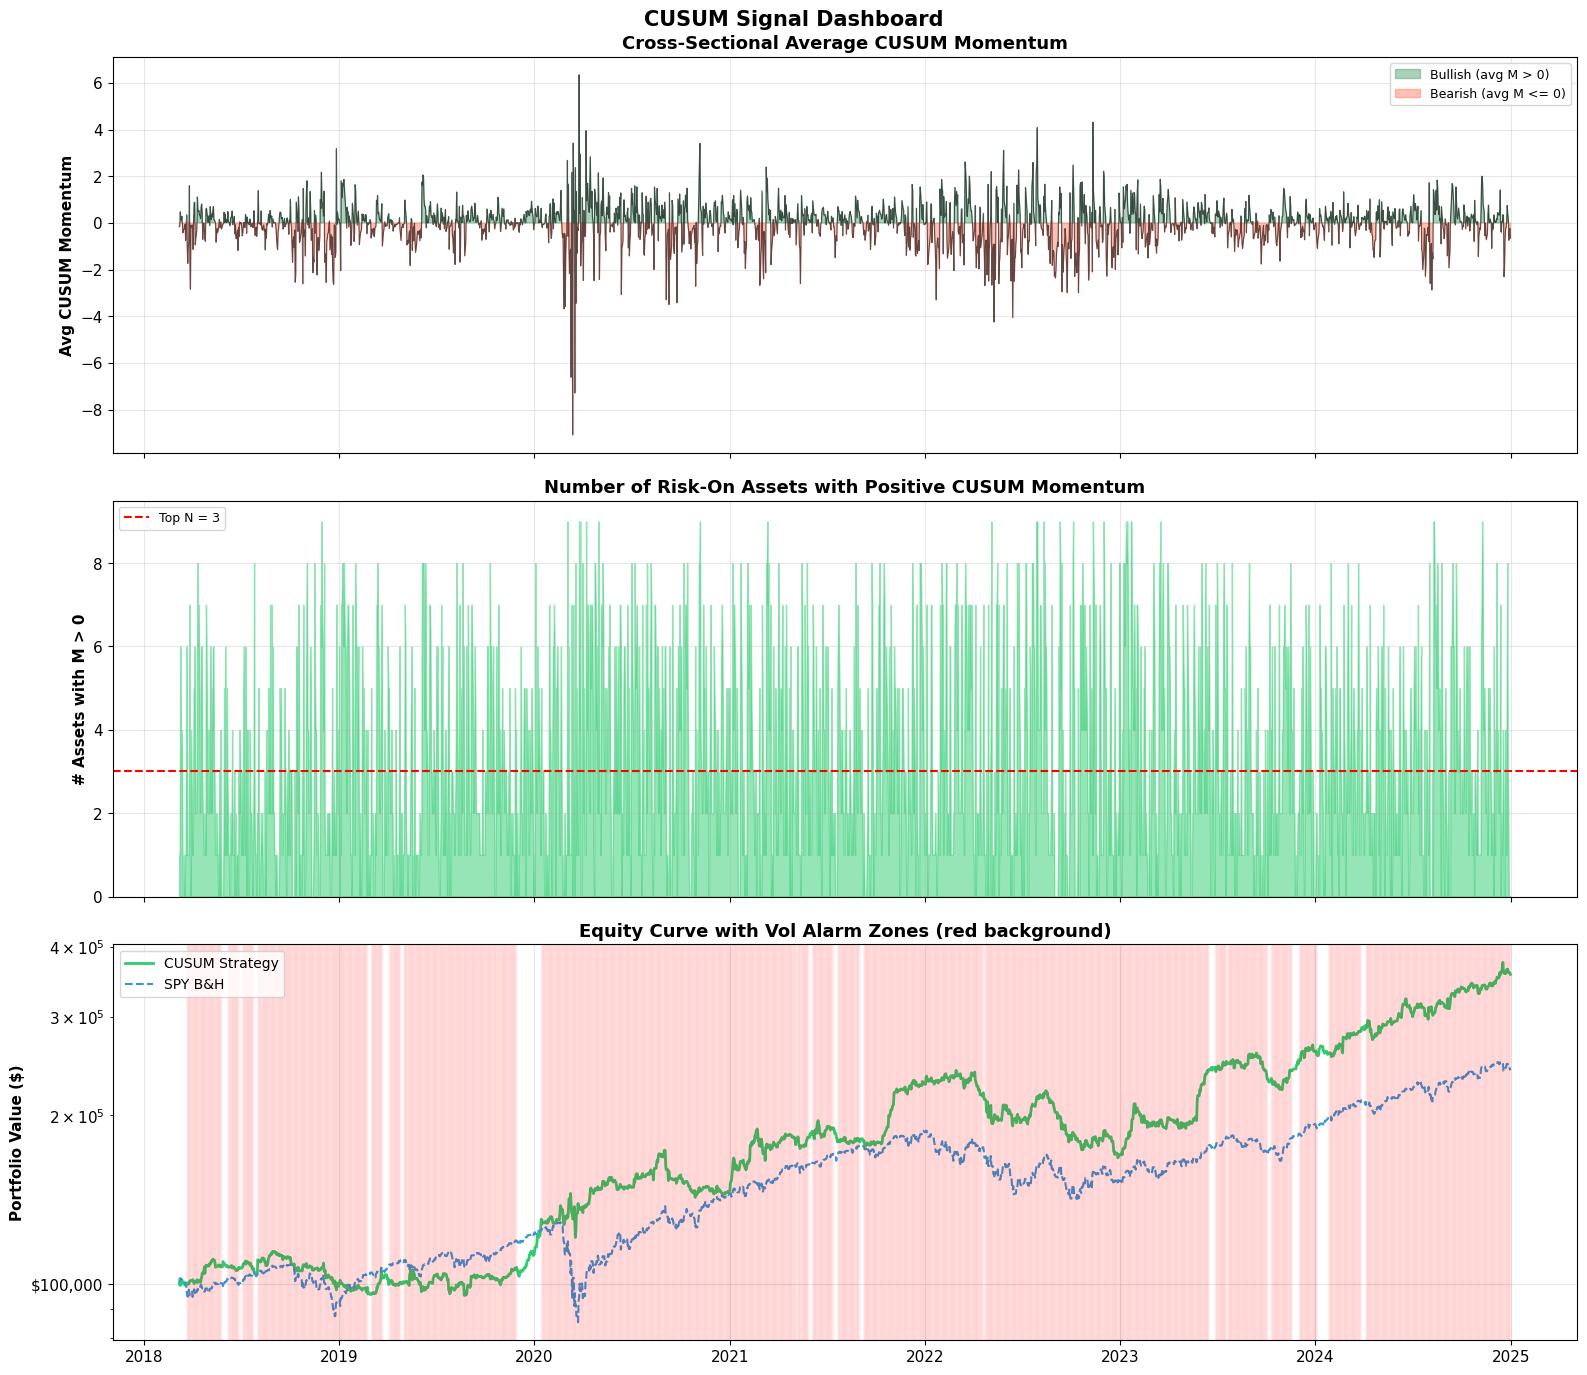

In [16]:
# ============================================================
#  CUSUM SIGNAL DASHBOARD
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)

# Panel 1: average CUSUM momentum across selected assets
avg_mom = cusum_df.mean(axis=1)
ax = axes[0]
ax.fill_between(avg_mom.index, avg_mom, 0,
                where=avg_mom > 0, alpha=0.4, color='seagreen', label='Bullish (avg M > 0)')
ax.fill_between(avg_mom.index, avg_mom, 0,
                where=avg_mom <= 0, alpha=0.4, color='tomato', label='Bearish (avg M <= 0)')
ax.plot(avg_mom.index, avg_mom, color='black', lw=0.8, alpha=0.6)
ax.set_ylabel('Avg CUSUM Momentum')
ax.set_title('Cross-Sectional Average CUSUM Momentum', fontsize=13)
ax.legend(fontsize=9)

# Panel 2: number of assets with positive momentum
n_positive = (cusum_df > MIN_SCORE).sum(axis=1)
ax2 = axes[1]
ax2.fill_between(n_positive.index, n_positive, alpha=0.5, color='#2ecc71')
ax2.axhline(TOP_N, color='red', ls='--', lw=1.5, label=f'Top N = {TOP_N}')
ax2.set_ylabel('# Assets with M > 0')
ax2.set_title('Number of Risk-On Assets with Positive CUSUM Momentum', fontsize=13)
ax2.set_ylim(0, len(RISK_ON) + 0.5)
ax2.legend(fontsize=9)

# Panel 3: equity curve with vol alarm overlay
ax3 = axes[2]
ax3.plot(equity.index, equity, color='#2ecc71', lw=2, label='CUSUM Strategy')
ax3.plot(spy_equity.index, spy_equity, color='#3498db', lw=1.5, ls='--', label='SPY B&H')
# Shade vol alarm periods (any asset)
any_alarm = vol_alarm_df.any(axis=1).reindex(equity.index).fillna(False)
for idx in equity.index:
    if idx in any_alarm.index and any_alarm.loc[idx]:
        ax3.axvline(idx, color='red', alpha=0.03, lw=2)
ax3.set_yscale('log')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'${y:,.0f}'))
ax3.set_ylabel('Portfolio Value ($)')
ax3.set_title('Equity Curve with Vol Alarm Zones (red background)', fontsize=13)
ax3.legend(fontsize=10)

plt.suptitle('CUSUM Signal Dashboard', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

## 6. Rebalance Log

In [17]:
# ============================================================
#  REBALANCE LOG -- LAST 20
# ============================================================

print(f'Last 20 of {len(rebal_log)} rebalances:\n')
print(f'{"Date":>12} | {"Risk-On":>8} | {"TLT Wt":>7} | {"VolGate":>7} | Selected Assets (CUSUM momentum)')
print('=' * 90)
for r in rebal_log[-20:]:
    d = r['date'].strftime('%Y-%m-%d')
    a = ', '.join(f"{t}({r['cusum_scores'][t]:.2f})" for t in r['selected'])
    if not a:
        a = '(none -- 100% TLT)'
    vg = r['vol_gated']
    print(f'{d:>12} | {r["n_selected"]:>8} | {r["tlt_weight"]:>7.1%} | {vg:>7} | {a}')

Last 20 of 250 rebalances:

        Date |  Risk-On |  TLT Wt | VolGate | Selected Assets (CUSUM momentum)
  2024-06-24 |        0 |  100.0% |       0 | (none -- 100% TLT)
  2024-07-04 |        3 |   33.3% |       2 | TSLA(2.64), AAPL(2.08), GLD(1.54)
  2024-07-14 |        1 |   83.3% |       1 | GLD(1.69)
  2024-07-24 |        1 |   66.7% |       0 | NVDA(0.38)
  2024-08-03 |        0 |  100.0% |       0 | (none -- 100% TLT)
  2024-08-13 |        3 |   50.0% |       3 | GLD(3.82), NVDA(1.06), AAPL(0.41)
  2024-08-23 |        0 |  100.0% |       0 | (none -- 100% TLT)
  2024-09-02 |        2 |   33.3% |       0 | TSLA(0.30), AMZN(0.12)
  2024-09-12 |        3 |   33.3% |       2 | NVDA(3.54), AMZN(2.63), TSLA(2.40)
  2024-09-22 |        3 |   16.7% |       1 | AAPL(1.60), TSLA(0.60), XLE(0.56)
  2024-10-02 |        2 |   50.0% |       1 | XLE(2.02), GLD(1.40)
  2024-10-12 |        3 |    0.0% |       0 | GLD(2.30), XLE(0.72), BTC-USD(0.12)
  2024-10-22 |        2 |   33.3% |       0 | 

## 7. Key Takeaways

### Lookahead Bias Prevention

This backtest is **lookahead-free**:
- CUSUM at day $t$ uses returns from the burn-in window onwards -- all known at close of $t$
- In-control parameters ($\hat\mu_0, \hat\sigma_0$) estimated from the first 63 returns only
- Signal is **shifted by 1 day** (`cusum_df = cusum_raw.shift(1)`)
- On rebalance day $t$, the backtest sees CUSUM momentum from day $t-1$
- Weights are applied to day $t$'s return (close $t-1$ to close $t$)

### CUSUM vs Hurst for Asset Selection

| Dimension | Hurst | CUSUM |
|-----------|-------|-------|
| Signal meaning | "How persistent is this series?" | "Is there active drift right now?" |
| Stale signal risk | High (63d window = slow) | Low (resets on alarm) |
| Directional info | No (scalar 0-1) | Yes (C+ - C- is signed) |
| False alarm control | Heuristic (H > 0.5) | Calibrated via ARL0(k, h) |
| Computational cost | O(n log n) per window | O(n) streaming |

### Volatility Gating

- The vol gate uses a **one-sided CUSUM on squared returns** to detect volatility spikes
- When an alarm fires, the affected asset's weight is **halved** for 21 days
- The freed weight flows to **TLT**, providing automatic de-risking
- This acts as a **volatility-aware risk overlay** on top of the momentum signal

### TLT Risk-Off Mechanism
- Acts as **flight-to-quality** during uncertain regimes (no positive CUSUM momentum)
- Bonds often rally during equity drawdowns -- natural hedging
- Partial TLT allocation (1/3, 2/3) allows gradual risk scaling

### Potential Improvements

| Enhancement | Description |
|-------------|-------------|
| Adaptive k, h | Walk-forward optimisation of CUSUM parameters |
| Multi-timeframe | Average momentum across 21d, 63d, 126d burn-ins |
| Momentum weighting | Weight by CUSUM score instead of equal-weight |
| Transaction costs | Add slippage + commission modeling |
| Short leg | Short bottom 3 (strongest negative momentum) |
| Regime overlay | Combine with Hurst (trend in trending assets only) |
| Sector diversification | Constrain max sector exposure |